## pandas
pandas 库是以numpy为基础构建出来的数据可视化工具（应该吧

构建dataframe类,dataframe是用来高效处理表格数据的类

In [1]:
import pandas as pd
df = pd.DataFrame([10, 20, 30 ,40],columns= ["numbers"], index= ['a','b', 'c', 'd'])
df['floats'] = (1.1, 4.5, 1.4, 1.9)
#或者
df['names']= pd.DataFrame(['Yves', 'Sandra', 'Lilli', 'Henry'],index = ['b','c','a','d'])
#不能在括号里面输入columns 需要在括号外才表示添加df = pd.DataFrame(['Yves', 'Sandra', 'Lilli', 'Henry'],columns=['names'],index = ['b','c','a','d'])
df

,numbers,floats,names
a,10,1.1,Lilli
b,20,4.5,Yves
c,30,1.4,Sandra
d,40,1.9,Henry


In [2]:
import numpy as np
np.random.seed(100) #这是一个(假)的随机数生成器，因为它可以指定种子seed(100)生成相同的随机数
a = np.random.standard_normal((9,4))
df = pd.DataFrame(a)
df.columns = ['no.1','no.2','no.3','no.4']
df

,no.1,no.2,no.3,no.4
0,-1.749765,0.342680,1.153036,-0.252436
1,0.981321,0.514219,0.221180,-1.070043
2,-0.189496,0.255001,-0.458027,0.435163
3,-0.583595,0.816847,0.672721,-0.104411
4,-0.531280,1.029733,-0.438136,-1.118318
5,1.618982,1.541605,-0.251879,-0.842436
6,0.184519,0.937082,0.731000,1.361556
7,-0.326238,0.055676,0.222400,-1.443217
8,-0.756352,0.816454,0.750445,-0.455947


In [3]:
dates = pd.date_range('2026-10-9',periods=9,freq='ME')
df.index = dates
df

,no.1,no.2,no.3,no.4
2026-10-31,-1.749765,0.342680,1.153036,-0.252436
2026-11-30,0.981321,0.514219,0.221180,-1.070043
2026-12-31,-0.189496,0.255001,-0.458027,0.435163
2027-01-31,-0.583595,0.816847,0.672721,-0.104411
2027-02-28,-0.531280,1.029733,-0.438136,-1.118318
2027-03-31,1.618982,1.541605,-0.251879,-0.842436
2027-04-30,0.184519,0.937082,0.731000,1.361556
2027-05-31,-0.326238,0.055676,0.222400,-1.443217
2027-06-30,-0.756352,0.816454,0.750445,-0.455947


In [4]:
df.describe()

,no.1,no.2,no.3,no.4
count,9.000000,9.000000,9.000000,9.000000
mean,-0.150212,0.701033,0.289193,-0.387788
std,0.988306,0.457685,0.579920,0.877532
min,-1.749765,0.055676,-0.458027,-1.443217
25%,-0.583595,0.342680,-0.251879,-1.070043
50%,-0.326238,0.816454,0.222400,-0.455947
75%,0.184519,0.937082,0.731000,-0.104411
max,1.618982,1.541605,1.153036,1.361556


<Axes: >

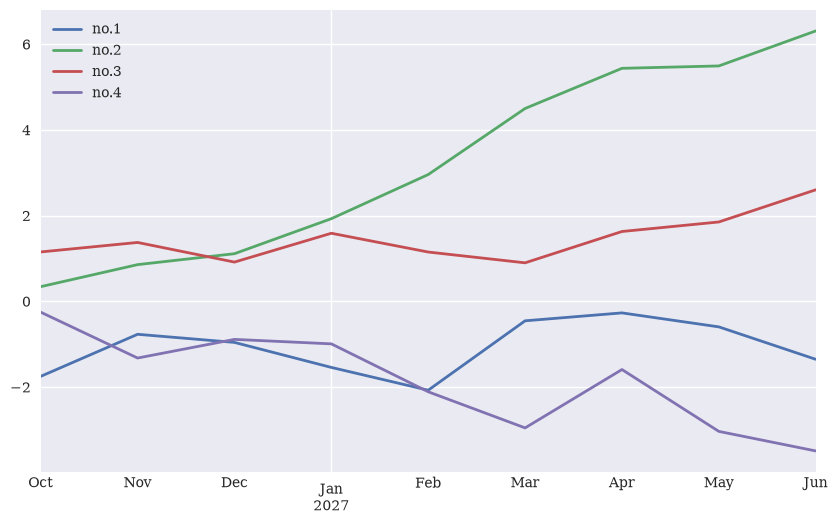

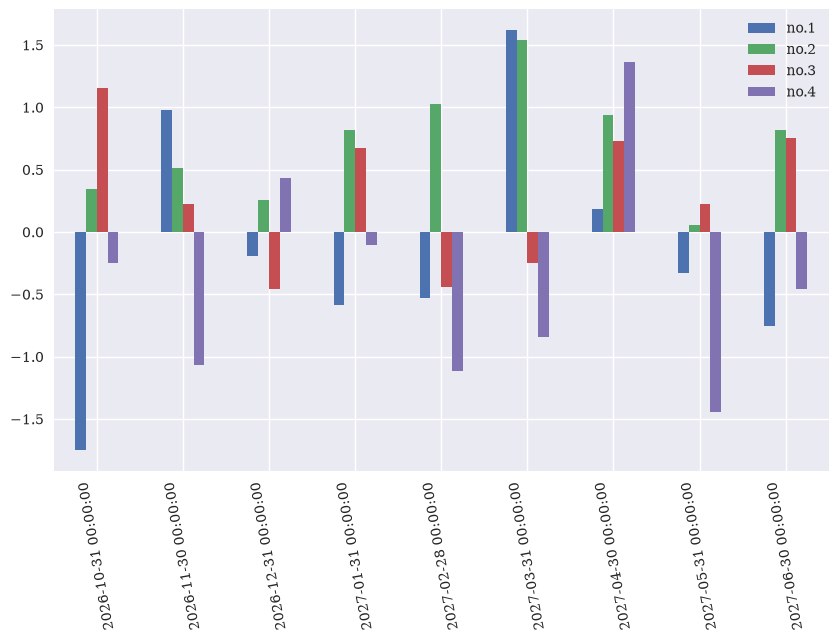

In [5]:
from pylab import plt,mpl
plt.style.use('seaborn-v0_8')
mpl.rcParams['font.family'] = 'serif'
%matplotlib inline
df.cumsum().plot(lw=2.0,figsize=(10,6))#cumsum()的作用是把数据进行累计和

df.plot.bar(figsize=(10,6),rot = 100)#figsize设置的是表格的大小，这里设置的是10英寸宽，6英寸高
#rot是rotation的缩写，表示x轴标签的旋转角度


In [6]:
type(df)

pandas.DataFrame

### SERIES类
他的特点是只有一列数据

In [7]:
S = pd.Series(np.linspace(0,15,7),name = 'series')#linspace linear space 线性等距空间
S

0     0.0
1     2.5
2     5.0
3     7.5
4    10.0
5    12.5
6    15.0
Name: series, dtype: float64

In [8]:
s = df['no.1']
s

2026-10-31   -1.749765
2026-11-30    0.981321
2026-12-31   -0.189496
2027-01-31   -0.583595
2027-02-28   -0.531280
2027-03-31    1.618982
2027-04-30    0.184519
2027-05-31   -0.326238
2027-06-30   -0.756352
Freq: ME, Name: no.1, dtype: float64

<Axes: >

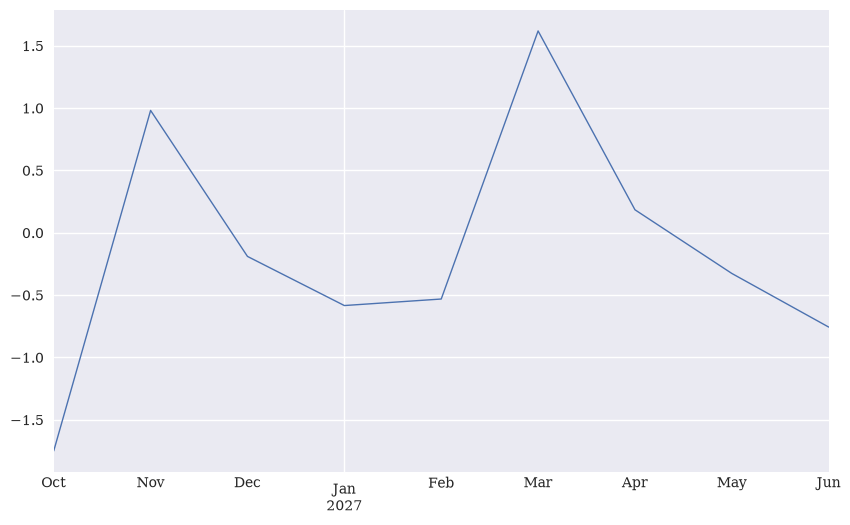

In [9]:
s.plot(figsize=(10,6),lw =1)

### GroupBy操作
为了进行分组，我们添加一列，表示对应索引数据所属的季度：

In [10]:
df['Quarter'] = ['Q1','Q1','Q1','Q2','Q2','Q2','Q3','Q3','Q3']
df

,no.1,no.2,no.3,no.4,Quarter
2026-10-31,-1.749765,0.342680,1.153036,-0.252436,Q1
2026-11-30,0.981321,0.514219,0.221180,-1.070043,Q1
2026-12-31,-0.189496,0.255001,-0.458027,0.435163,Q1
2027-01-31,-0.583595,0.816847,0.672721,-0.104411,Q2
2027-02-28,-0.531280,1.029733,-0.438136,-1.118318,Q2
2027-03-31,1.618982,1.541605,-0.251879,-0.842436,Q2
2027-04-30,0.184519,0.937082,0.731000,1.361556,Q3
2027-05-31,-0.326238,0.055676,0.222400,-1.443217,Q3
2027-06-30,-0.756352,0.816454,0.750445,-0.455947,Q3


In [11]:
groups = df.groupby('Quarter')
groups.size()

Quarter
Q1    3
Q2    3
Q3    3
dtype: int64

In [12]:
groups.mean()

,no.1,no.2,no.3,no.4
Quarter,,,,
Q1,-0.319314,0.370634,0.305396,-0.295772
Q2,0.168035,1.129395,-0.005765,-0.688388
Q3,-0.299357,0.603071,0.567948,-0.179203


In [13]:
groups.max()

,no.1,no.2,no.3,no.4
Quarter,,,,
Q1,0.981321,0.514219,1.153036,0.435163
Q2,1.618982,1.541605,0.672721,-0.104411
Q3,0.184519,0.937082,0.750445,1.361556


In [14]:
groups.aggregate([min, max]).round(2)

no.1        no.2        no.3        no.4      
          min   max   min   max   min   max   min   max
Quarter                                                
Q1      -1.75  0.98  0.26  0.51 -0.46  1.15 -1.07  0.44
Q2      -0.58  1.62  0.82  1.54 -0.44  0.67 -1.12 -0.10
Q3      -0.76  0.18  0.06  0.94  0.22  0.75 -1.44  1.36

### 复杂选择

In [15]:
np.random.seed(114514)
data = np.random.standard_normal((10,2))
data

array([[ 1.11490901,  1.1882115 ],
       [ 1.41804512, -0.36769038],
       [ 0.24881411,  0.38049812],
       [ 0.6352939 , -1.09419838],
       [ 0.44031896, -0.84903172],
       [ 1.5081906 , -0.68171421],
       [ 0.06852704, -0.57467491],
       [-0.53778764, -0.60896204],
       [-0.64299123,  0.23048472],
       [ 1.17533925,  0.58298367]])

In [16]:
df = pd.DataFrame(data,columns=['x','y'])
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   x       10 non-null     float64
 1   y       10 non-null     float64
dtypes: float64(2)
memory usage: 292.0 bytes


In [17]:
df['x'] > 0.5

0     True
1     True
2    False
3     True
4    False
5     True
6    False
7    False
8    False
9     True
Name: x, dtype: bool

In [18]:
df[df['x'] > 0] #等价于df.query('x > 0')

,x,y
0,1.114909,1.188212
1,1.418045,-0.367690
2,0.248814,0.380498
3,0.635294,-1.094198
4,0.440319,-0.849032
5,1.508191,-0.681714
6,0.068527,-0.574675
9,1.175339,0.582984


In [ ]:
df1 = pd.DataFrame([100,200,300,400], index=['a', 'b', 'c', 'd'], columns=['A',]) 
df2 =pd.DataFrame([200,150,50],index=['f','b','d'],columns=['B',])
#df1.append(df2,sort = False) 这个方法已经被去掉了
print(pd.concat((df1,df2),sort = False))#这个只是简单地在下面粘上去
print(df1.join(df2,how='outer'))#这个则是把已有的指标合并了
df1.join(df2) #只是把df2中有的加进到df1中，剩下的不管，df2.join(df1)同理

       A      B
a  100.0    NaN
b  200.0    NaN
c  300.0    NaN
d  400.0    NaN
f    NaN  200.0
b    NaN  150.0
d    NaN   50.0
       A      B
a  100.0    NaN
b  200.0  150.0
c  300.0    NaN
d  400.0   50.0
f    NaN  200.0


,A,B
a,100,NaN
b,200,150.0
c,300,NaN
d,400,50.0
